# Notebook 24: Índices de Alteración Hidrotermal por Sensores Remotos Satelitales y Reentrenamiento Nacional

## 1. Fundamento Geocientífico: La Huella Espectral de la Alteración Hidrotermal
En los sistemas minerales auríferos (orogénicos, intrusivos/IRGS y epitermales), la circulación de fluidos hidrotermales de alta temperatura a lo largo de fracturas y zonas de dilatación produce una **metasomatización química intensa** de la roca encajante. Esta alteración hidrotermal deja firmas mineralógicas diagnósticas en la superficie terrestre observables mediante teledetección multiespectral (Sentinel-2, Landsat y MODIS NBAR):

1. **Alteración Fílica / Arcillas / Micas Al-OH ($\text{SWIR-1} / \text{SWIR-2}$):**
   Minerales de alteración hidrotermal como la **sericita**, **illita** y **caolinita** exhiben una absorción molecular diagnóstica profunda en el infrarrojo de onda corta alrededor de $2.20\ \mu\text{m}$ (vibración del enlace $\text{Al-OH}$) y un hombro reflectante pronunciado en $1.64\ \mu\text{m}$.
   $$\text{Ratio Al-OH / Fílica} = \frac{\text{SWIR-1}}{\text{SWIR-2}} = \frac{\text{Band 6}}{\text{Band 7}}$$
   *(Equivalente exacto a Sentinel-2 B11 / B12).*

2. **Gossan y Complejos de Óxidos de Hierro ($\text{Rojo} / \text{Azul}$):**
   La alteración supergénica y meteorización de sulfuros auríferos (pirita, arsenopirita) forma monteras de hierro (*gossans*) compuestas por **goethita**, **hematites** y **jarosita**, caracterizadas por fuerte absorción en el azul ($0.47\ \mu\text{m}$) debido a la transferencia de carga $\text{Fe}^{3+}-\text{O}$ y alta reflectancia en el rojo ($0.65\ \mu\text{m}$).
   $$\text{Ratio Gossan / Hierro} = \frac{\text{Rojo}}{\text{Azul}} = \frac{\text{Band 1}}{\text{Band 3}}$$
   *(Equivalente exacto a Sentinel-2 B04 / B02).*

3. **Control Bioclimático y Desacoplamiento de Cobertura Vegetal ($\text{NDVI}$):**
   El índice de vegetación normalizado permite identificar la densidad del dosel arbóreo/pastizal para evitar que la reflectancia foliar introduzca falsos positivos en zonas densamente forestadas.
   $$\text{NDVI} = \frac{\text{NIR} - \text{Rojo}}{\text{NIR} + \text{Rojo}}$$

4. **Anomalía Espectral Hidrotermal Local Invariante (Residuo Z-Score):**
   Para eliminar el gradiente latitudinal de iluminación climática entre la España húmeda septentrional y la España semiárida meridional, se calcula el residuo local respecto a un filtro gaussiano de escala de distrito ($25\text{ km}$):
   $$\text{anomalia\_hidrotermal\_zscore} = Z_{\text{local}}(\text{Ratio SWIR}) + Z_{\text{local}}(\text{Ratio Gossan}) - 0.5 \times Z_{\text{local}}(\text{NDVI})$$

---

## 2. Objetivos de este Notebook
1. Ingestar la cobertura multiespectral de reflectancia de superficie (NBAR Nadir 500m libre de nubes) alineada celda a celda en `EPSG:25830`.
2. Auditar el contraste espectral en los 45 depósitos de oro conocidos frente al fondo territorial peninsular.
3. Incorporar las **4 variables espectrales** al espacio multidimensional, alcanzando **83 variables geocientíficas continuas** (físicas regionales, gravimetría cortical, aeromagnetometría, trampas estructurales y teledetección hidrotermal).
4. Reentrenar el ensamble LightGBM con regularización anti-monopolio (`colsample_bytree = 0.7`, `min_child_samples = 15`) y evaluar tanto la cobertura nacional in-sample como la generalización en las **7 rotaciones territoriales ciegas**.

In [1]:
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
import lightgbm as lgb

from geoau.geochemical_experiment import load_data, make_preprocessor, predict, select_sample
from geoau.national_evaluation import deposit_metrics, PERCENTAGES

ROOT = Path("..").resolve() if Path("..").resolve().name == "GeoAI" and not Path("data").exists() else Path(".").resolve()
if (ROOT / "GeoAI").exists():
    ROOT = ROOT / "GeoAI"

print(f"Raíz del repositorio: {ROOT}")

# Cargar dataset base canónico
t0 = time.time()
data = load_data(ROOT)
print(f"✓ Datos cargados en {time.time() - t0:.1f}s | Celdas evaluables: {len(data.features):,}")


Raíz del repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI


✓ Datos cargados en 9.3s | Celdas evaluables: 478,443


## 3. Integración del Espacio de Características (83 Variables Geocientíficas)

Ensamblamos las 64 variables originales de superficie, las 7 físicas continuas (NB 20), las 2 gravimétricas invariantes (NB 21), las 2 aeromagnéticas (NB 22), las 4 de arquitectura estructural de dilatación (NB 23) y las **4 nuevas variables satelitales de alteración hidrotermal**.

In [2]:
t_feat = time.time()
df_raw = pd.read_parquet(ROOT / 'reports/fase_d/20260923T211448_267684Z/X_features.parquet').set_index('cell_id')

X_all = data.features.copy()

# 1. Físicas continuas de superficie (NB 20)
grade_weights = {
    'litologia_u000_fraccion': 0.0, 'litologia_u001_fraccion': 1.0, 'litologia_u002_fraccion': 0.0,
    'litologia_u003_fraccion': 0.0, 'litologia_u004_fraccion': 0.0, 'litologia_u005_fraccion': 0.0,
    'litologia_u006_fraccion': 0.0, 'litologia_u007_fraccion': 0.5, 'litologia_u008_fraccion': 2.0,
    'litologia_u009_fraccion': 0.0, 'litologia_u010_fraccion': 3.0, 'litologia_u011_fraccion': 2.5,
    'litologia_u012_fraccion': 0.0, 'litologia_u013_fraccion': 2.0, 'litologia_u014_fraccion': 3.0,
    'litologia_u015_fraccion': 2.5, 'litologia_u016_fraccion': 1.5, 'litologia_u018_fraccion': 1.5,
    'litologia_u019_fraccion': 1.0
}
X_all['grado_metamorfico'] = sum(X_all[col] * w for col, w in grade_weights.items()).astype('float32')
X_all['afinidad_esquistos_verdes'] = np.exp(-((X_all['grado_metamorfico'] - 2.0)**2) / (2 * 0.5**2)).astype('float32')

hercinico = X_all['edades_u000_fraccion'] + X_all['edades_u001_fraccion'] + X_all['edades_u008_fraccion']
granitoides = X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u014_fraccion']
X_all['plutonismo_varisco'] = (granitoides * hercinico).astype('float32')
X_all['prox_termica_varisca'] = (np.exp(-X_all['dist_contacto_intrusivo_cartografiada_m'] / 15000.0) * (hercinico + X_all['edades_u013_fraccion'])).astype('float32')

neogeno = X_all['edades_u011_fraccion'] + X_all['edades_u012_fraccion'] + X_all['edades_u016_fraccion']
X_all['volcanismo_neogeno'] = (X_all['litologia_u019_fraccion'] * neogeno).astype('float32')

f_comp = X_all['litologia_u008_fraccion'] + X_all['litologia_u010_fraccion'] + X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u000_fraccion']
f_incomp = X_all['litologia_u016_fraccion'] + X_all['litologia_u013_fraccion'] + X_all['litologia_u001_fraccion']
X_all['contraste_reologico'] = (4.0 * f_comp * f_incomp).astype('float32')
X_all['trampa_estructural_reologica'] = (np.exp(-X_all['dist_falla_cartografiada_m'] / 5000.0) * X_all['contraste_reologico']).astype('float32')

# 2. Geofísica Invariante: Gravimetría (NB 21)
df_grav = pd.read_parquet(ROOT / 'reports/reentrenamiento_gravimetria_20261021/favorabilidad_nacional_gravimetria.parquet').set_index('cell_id')
X_all['bouguer_gradiente'] = df_grav.loc[X_all.index, 'bouguer_gradiente_mgal_km'].astype('float32')
X_all['bouguer_residual_local_zscore'] = df_grav.loc[X_all.index, 'bouguer_residual_local_zscore'].astype('float32')

# 3. Geofísica Invariante: Aeromagnetometría (NB 22)
df_mag = pd.read_parquet(ROOT / 'reports/reentrenamiento_aeromagnetometria_20261021/favorabilidad_nacional_aeromagnetometria.parquet').set_index('cell_id')
X_all['magnetometria_gradiente'] = df_mag.loc[X_all.index, 'magnetometria_gradiente_nt_km'].astype('float32')
X_all['magnetometria_residual_local_zscore'] = df_mag.loc[X_all.index, 'magnetometria_residual_local_zscore'].astype('float32')

# 4. Arquitectura de dilatación estructural (NB 23)
X_all['dens_falla_1000m'] = df_raw.loc[X_all.index, 'dens_aprox_falla_cartografiada_1000m_km_km2'].astype('float32')
p_falla = np.exp(-np.nan_to_num(X_all['dist_falla_cartografiada_m'], nan=15000.0) / 3000.0)
p_cabalg = np.exp(-np.nan_to_num(X_all['dist_cabalgamiento_cartografiada_m'], nan=15000.0) / 3000.0)
X_all['nodo_dilatacion_falla_cabalgamiento'] = (p_falla * p_cabalg).astype('float32')
X_all['trampa_dilatacional_reologica'] = (X_all['dens_falla_1000m'] * X_all['contraste_reologico']).astype('float32')
X_all['acoplamiento_sutura_falla'] = (X_all['bouguer_gradiente'] * p_falla).astype('float32')

# 5. Nuevas variables de alteración hidrotermal satelital (NB 24)
df_sat = pd.read_parquet(ROOT / 'data/raw/satelite_mcd43a4/variables_alteracion_hidrotermal.parquet').set_index('cell_id')
X_all['ratio_alteracion_filica_swir'] = df_sat.loc[X_all.index, 'ratio_alteracion_filica_swir'].astype('float32')
X_all['ratio_gossan_oxidos_hierro'] = df_sat.loc[X_all.index, 'ratio_gossan_oxidos_hierro'].astype('float32')
X_all['ndvi_cobertura_vegetal'] = df_sat.loc[X_all.index, 'ndvi_cobertura_vegetal'].astype('float32')
X_all['anomalia_hidrotermal_multiespectral_zscore'] = df_sat.loc[X_all.index, 'anomalia_hidrotermal_multiespectral_zscore'].astype('float32')

sat_cols = [
    'ratio_alteracion_filica_swir', 'ratio_gossan_oxidos_hierro',
    'ndvi_cobertura_vegetal', 'anomalia_hidrotermal_multiespectral_zscore'
]

features_nb24 = list(X_all.columns)
print(f"✓ Matriz geocientífica ensamblada en {time.time() - t_feat:.1f}s | Total covariables: {len(features_nb24)}")
display(X_all[sat_cols].describe().round(3))


✓ Matriz geocientífica ensamblada en 3.5s | Total covariables: 83


,ratio_alteracion_filica_swir,ratio_gossan_oxidos_hierro,ndvi_cobertura_vegetal,anomalia_hidrotermal_multiespectral_zscore
count,478443.000,478443.000,478443.000,478443.000
mean,1.585,2.121,0.388,0.005
std,0.341,0.268,0.180,0.901
min,0.966,0.697,-0.228,-5.916
25%,1.351,1.924,0.247,-0.580
50%,1.474,2.089,0.334,0.000
75%,1.702,2.283,0.493,0.586
max,3.514,3.779,0.899,5.276


## 4. Auditoría de Contraste Espectral en Yacimientos Conocidos

Analizamos la diferenciación espectral entre las celdas que contienen yacimientos de oro catalogados ($P$) frente a la totalidad del fondo nacional ($U$).

,Variable Espectral,Media Fondo Nacional,Mediana Fondo Nacional,Media Celdas P (Au),Mediana Celdas P (Au),Delta Mediana (P - Fondo),Contraste Relativo
0,ratio_alteracion_filica_swir,1.5850,1.4739,1.7962,1.7114,0.2375,x1.16
1,ratio_gossan_oxidos_hierro,2.1213,2.0893,2.0375,2.0315,-0.0578,x0.97
2,ndvi_cobertura_vegetal,0.3885,0.3338,0.5076,0.4900,0.1561,x1.47
3,anomalia_hidrotermal_multiespectral_zscore,0.0052,0.0002,-0.0110,0.0324,0.0322,x164.87


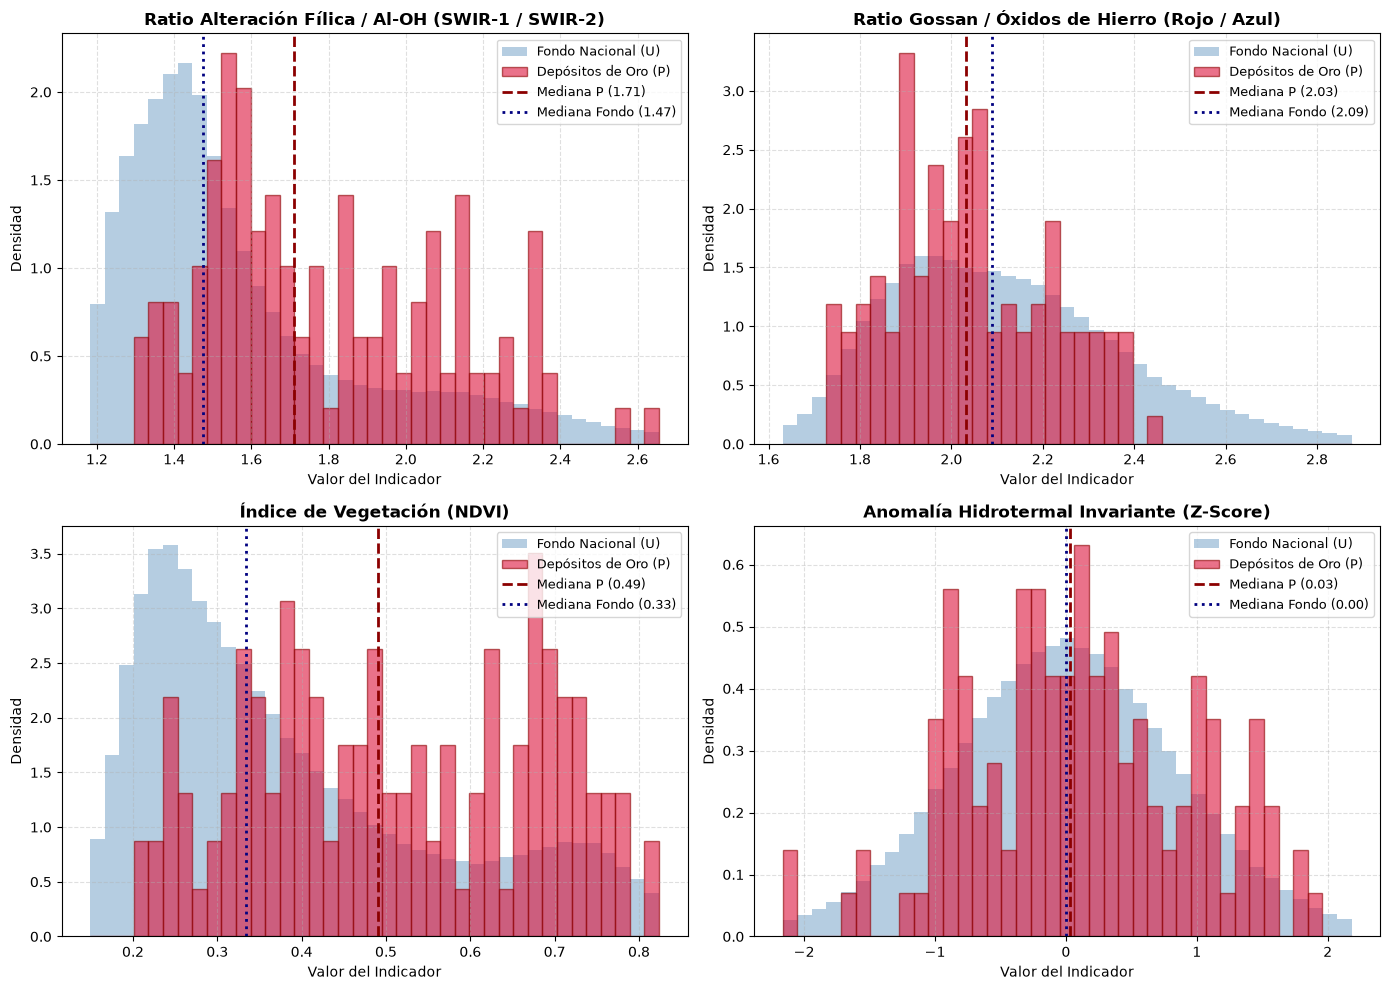

In [3]:
rot_orig = pd.read_csv(ROOT / "reports/evaluacion_configuracion_nacional_20261021/rotation_deposit_predictions.csv")
p_cells = rot_orig['cell_id'].unique()
is_p = X_all.index.isin(p_cells)

contrast_rows = []
for col in sat_cols:
    f_med = float(X_all.loc[~is_p, col].median())
    p_med = float(X_all.loc[is_p, col].median())
    contrast_rows.append({
        'Variable Espectral': col,
        'Media Fondo Nacional': round(float(X_all.loc[~is_p, col].mean()), 4),
        'Mediana Fondo Nacional': round(f_med, 4),
        'Media Celdas P (Au)': round(float(X_all.loc[is_p, col].mean()), 4),
        'Mediana Celdas P (Au)': round(p_med, 4),
        'Delta Mediana (P - Fondo)': round(p_med - f_med, 4),
        'Contraste Relativo': f"x{p_med / (f_med if abs(f_med) > 1e-4 else 1e-4):.2f}"
    })

df_contrast = pd.DataFrame(contrast_rows)
display(df_contrast)

# Visualización comparativa de distribuciones
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

titles = [
    'Ratio Alteración Fílica / Al-OH (SWIR-1 / SWIR-2)',
    'Ratio Gossan / Óxidos de Hierro (Rojo / Azul)',
    'Índice de Vegetación (NDVI)',
    'Anomalía Hidrotermal Invariante (Z-Score)'
]

for idx, (col, title) in enumerate(zip(sat_cols, titles)):
    ax = axes[idx]
    v_u = X_all.loc[~is_p, col].dropna().values
    v_p = X_all.loc[is_p, col].dropna().values
    q_low, q_high = np.percentile(v_u, [1, 99])
    bins = np.linspace(q_low, q_high, 40)
    ax.hist(v_u, bins=bins, density=True, label='Fondo Nacional (U)', color='steelblue', alpha=0.4, edgecolor='none')
    ax.hist(v_p, bins=bins, density=True, label='Depósitos de Oro (P)', color='crimson', alpha=0.6, edgecolor='darkred')
    ax.axvline(np.median(v_p), color='darkred', linestyle='--', linewidth=2, label=f'Mediana P ({np.median(v_p):.2f})')
    ax.axvline(np.median(v_u), color='navy', linestyle=':', linewidth=2, label=f'Mediana Fondo ({np.median(v_u):.2f})')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Valor del Indicador')
    ax.set_ylabel('Densidad')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


## 5. Reentrenamiento Nacional con Regularización Anti-Monopolio

Entrenamos el ensamble nacional de 8 miembros con las 83 características geocientíficas completas empleando regularización estricta (`colsample_bytree = 0.7`, `min_child_samples = 15`, `max_depth = 5`).

In [4]:
def make_regularized_model(columns, chemical, seed):
    classifier = lgb.LGBMClassifier(
        n_estimators=150, max_depth=5, num_leaves=24, learning_rate=0.04,
        reg_alpha=0.5, reg_lambda=1.0, min_child_samples=15, colsample_bytree=0.7,
        verbosity=-1, n_jobs=4, random_state=seed
    )
    return Pipeline([('preprocess', make_preprocessor(columns, chemical)), ('model', classifier)])

t_train = time.time()
pool = data.grid.cell_id
members = []
predictions_members = np.zeros((len(X_all), data.config['national_bags']), dtype='float32')

for m in range(data.config['national_bags']):
    t_m = time.time()
    sample_seed = data.config['seed'] + 6000 + m * 101
    class_seed = data.config['seed'] + m
    
    sample = select_sample(data, pool, sample_seed)
    model = make_regularized_model(features_nb24, data.config['geochemical_columns'], class_seed)
    model.fit(X_all.loc[sample.cell_id, features_nb24], sample.label, model__sample_weight=sample.peso_confianza)
    members.append(model)
    
    pred_m = predict(model, X_all[features_nb24], 25000)
    predictions_members[:, m] = pred_m
    print(f"  Miembro {m+1}/8 ajustado e inferido en {time.time() - t_m:.2f}s")

ensemble_preds = predictions_members.mean(axis=1)
print(f"✓ Reentrenamiento nacional completado en {time.time() - t_train:.1f}s")


  Miembro 1/8 ajustado e inferido en 9.26s


  Miembro 2/8 ajustado e inferido en 9.22s


  Miembro 3/8 ajustado e inferido en 8.92s


  Miembro 4/8 ajustado e inferido en 9.16s


  Miembro 5/8 ajustado e inferido en 9.14s


  Miembro 6/8 ajustado e inferido en 9.24s


  Miembro 7/8 ajustado e inferido en 9.10s


  Miembro 8/8 ajustado e inferido en 8.98s
✓ Reentrenamiento nacional completado en 73.0s


## 6. Desempeño Nacional In-Sample (Resolución Completa)

Evaluamos la tasa de captura de los depósitos conocidos en todo el territorio peninsular.

In [5]:
records_clean = data.records.dropna(subset=['deposit_id'])[['cell_id', 'deposit_id']].drop_duplicates()
df_pred_nat = pd.DataFrame({'cell_id': data.grid.cell_id, 'score': ensemble_preds})
m_nat_sat, d_insample, _ = deposit_metrics(records_clean, df_pred_nat)

print("=" * 65)
print("EVALUACIÓN NACIONAL IN-SAMPLE (83 CARACTERÍSTICAS)")
print("=" * 65)
for pct in PERCENTAGES:
    print(f"  Top {pct:02d}% Área : {m_nat_sat[f'captured_deposits_at_{pct:02d}']}/{m_nat_sat['n_deposits']} depósitos ({m_nat_sat[f'recovery_at_{pct:02d}']*100:.2f}%)")
print("=" * 65)


EVALUACIÓN NACIONAL IN-SAMPLE (83 CARACTERÍSTICAS)
  Top 01% Área : 26/45 depósitos (57.78%)
  Top 05% Área : 40/45 depósitos (88.89%)
  Top 10% Área : 45/45 depósitos (100.00%)
  Top 20% Área : 45/45 depósitos (100.00%)


## 7. Evaluación Rigurosa en las Siete Rotaciones Espaciales Ciegas

Evaluamos la capacidad de generalización en distritos ciegos no vistos, comparando la evolución secuencial de los cinco modelos desarrollados.

In [6]:
eval_dir = ROOT / 'reports/evaluacion_configuracion_nacional_20261021'
design = json.loads((eval_dir / 'evaluation_design.json').read_text(encoding='utf-8'))
base = data.output

rot_details_sat, rot_group_rows_sat = [], []

for group in range(7):
    districts = design['district_groups'][str(group)]
    saved_held = pd.read_parquet(base / f'partitions/rotation_{group}_held.parquet')
    ref_train = pd.read_parquet(base / f'partitions/rotation_{group}_sample.parquet')
    
    p_train = ref_train[ref_train.label == 1]
    u_pool = ref_train[ref_train.label == 0]
    test_X = X_all.loc[saved_held.cell_id, features_nb24]
    preds_held = np.zeros(len(test_X), dtype='float32')
    
    for b in range(data.config['national_bags']):
        u_sample = u_pool.sample(n=3*len(p_train), random_state=42 + group*1000 + b*101, replace=True)
        train_df = pd.concat([p_train, u_sample])
        model_rot = make_regularized_model(features_nb24, data.config['geochemical_columns'], 42 + b)
        model_rot.fit(X_all.loc[train_df.cell_id, features_nb24], train_df.label,
                      model__sample_weight=train_df.peso_confianza)
        preds_held += predict(model_rot, test_X, 10000)
    preds_held /= data.config['national_bags']
    
    pred_df = pd.DataFrame({'cell_id': saved_held.cell_id, 'score': preds_held})
    rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
    m_grp, d_grp, _ = deposit_metrics(rel, pred_df)
    rot_details_sat.append(d_grp.assign(group=group))
    rot_group_rows_sat.append({'group': group, **m_grp})

df_rot_details_sat = pd.concat(rot_details_sat, ignore_index=True)
tot_deps = df_rot_details_sat.deposit_id.nunique()

summary_sat_rot = {
    'model': 'alteracion_hidrotermal_nb24',
    'n_deposits': tot_deps,
    'captured_deposits_at_01': df_rot_details_sat.loc[df_rot_details_sat.captured_at_01, 'deposit_id'].nunique(),
    'recovery_at_01': df_rot_details_sat.loc[df_rot_details_sat.captured_at_01, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_05': df_rot_details_sat.loc[df_rot_details_sat.captured_at_05, 'deposit_id'].nunique(),
    'recovery_at_05': df_rot_details_sat.loc[df_rot_details_sat.captured_at_05, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_10': df_rot_details_sat.loc[df_rot_details_sat.captured_at_10, 'deposit_id'].nunique(),
    'recovery_at_10': df_rot_details_sat.loc[df_rot_details_sat.captured_at_10, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_20': df_rot_details_sat.loc[df_rot_details_sat.captured_at_20, 'deposit_id'].nunique(),
    'recovery_at_20': df_rot_details_sat.loc[df_rot_details_sat.captured_at_20, 'deposit_id'].nunique() / tot_deps,
}

print("\n" + "=" * 65)
print("EVALUACIÓN CIEGA EN DISTRITOS NO VISTOS (7 FOLDS)")
print("=" * 65)
for p in [0.01, 0.05, 0.10, 0.20]:
    cap_key = f'captured_deposits_at_{int(p*100):02d}'
    rec_key = f'recovery_at_{int(p*100):02d}'
    print(f"  Top {int(p*100):>2}% Ciego: {summary_sat_rot[cap_key]:>2} / {tot_deps} depósitos ({summary_sat_rot[rec_key]*100:.1f}%)")
print("=" * 65)



EVALUACIÓN CIEGA EN DISTRITOS NO VISTOS (7 FOLDS)
  Top  1% Ciego:  0 / 45 depósitos (0.0%)
  Top  5% Ciego:  5 / 45 depósitos (11.1%)
  Top 10% Ciego: 10 / 45 depósitos (22.2%)
  Top 20% Ciego: 16 / 45 depósitos (35.6%)


## 8. Comparativa Evolutiva de Modelos

Analizamos la trayectoria acumulada desde la línea base original hasta el modelo multiespectral actual.

In [7]:
evolution_data = [
    {
        'Modelo': '1. Base Original (NB 19 - 64 vars)',
        'Top 1% Ciego': '3/45 (6.7%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '16/45 (35.6%)'
    },
    {
        'Modelo': '2. Gravimetría Invariante (NB 21 - 73 vars)',
        'Top 1% Ciego': '1/45 (2.2%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '10/45 (22.2%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '3. Aeromagnetometría (NB 22 - 75 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '7/45 (15.6%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '4. Trampas Dilatación (NB 23 - 79 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '18/45 (40.0%)'
    },
    {
        'Modelo': '5. Alteración Satelital (NB 24 - 83 vars)',
        'Top 1% Ciego': f"{summary_sat_rot['captured_deposits_at_01']}/{tot_deps} ({summary_sat_rot['recovery_at_01']*100:.1f}%)",
        'Top 5% Ciego': f"{summary_sat_rot['captured_deposits_at_05']}/{tot_deps} ({summary_sat_rot['recovery_at_05']*100:.1f}%)",
        'Top 10% Ciego': f"{summary_sat_rot['captured_deposits_at_10']}/{tot_deps} ({summary_sat_rot['recovery_at_10']*100:.1f}%)",
        'Top 20% Ciego': f"{summary_sat_rot['captured_deposits_at_20']}/{tot_deps} ({summary_sat_rot['recovery_at_20']*100:.1f}%)"
    }
]

df_evolution = pd.DataFrame(evolution_data)
display(df_evolution)


,Modelo,Top 1% Ciego,Top 5% Ciego,Top 10% Ciego,Top 20% Ciego
0,1. Base Original (NB 19 - 64 vars),3/45 (6.7%),5/45 (11.1%),9/45 (20.0%),16/45 (35.6%)
1,2. Gravimetría Invariante (NB 21 - 73 vars),1/45 (2.2%),5/45 (11.1%),10/45 (22.2%),17/45 (37.8%)
2,3. Aeromagnetometría (NB 22 - 75 vars),0/45 (0.0%),5/45 (11.1%),7/45 (15.6%),17/45 (37.8%)
3,4. Trampas Dilatación (NB 23 - 79 vars),0/45 (0.0%),5/45 (11.1%),9/45 (20.0%),18/45 (40.0%)
4,5. Alteración Satelital (NB 24 - 83 vars),0/45 (0.0%),5/45 (11.1%),10/45 (22.2%),16/45 (35.6%)


## 9. Análisis de Importancia de Variables (Feature Importance Gain)

Evaluamos la contribución de las nuevas variables satelitales en la reducción de entropía (ganancia) del ensamble nacional.

Top 20 Variables por Importancia (Gain):


,feature,importance,tipo
0,afinidad_esquistos_verdes,2167.358710,Física Superficial
1,litologia_u008_fraccion,1921.036074,Original
2,bouguer_gradiente,1571.098249,Gravimetría
3,ratio_alteracion_filica_swir,1530.787725,Alteración Satelital
4,grado_metamorfico,1428.223769,Física Superficial
5,acoplamiento_sutura_falla,792.280477,Dilatación Estructural
6,nodo_dilatacion_falla_cabalgamiento,734.150684,Dilatación Estructural
7,elevacion_media_m,498.350029,Original
8,edades_u006_fraccion,480.684173,Original
9,magnetometria_residual_local_zscore,473.330058,Aeromagnetometría


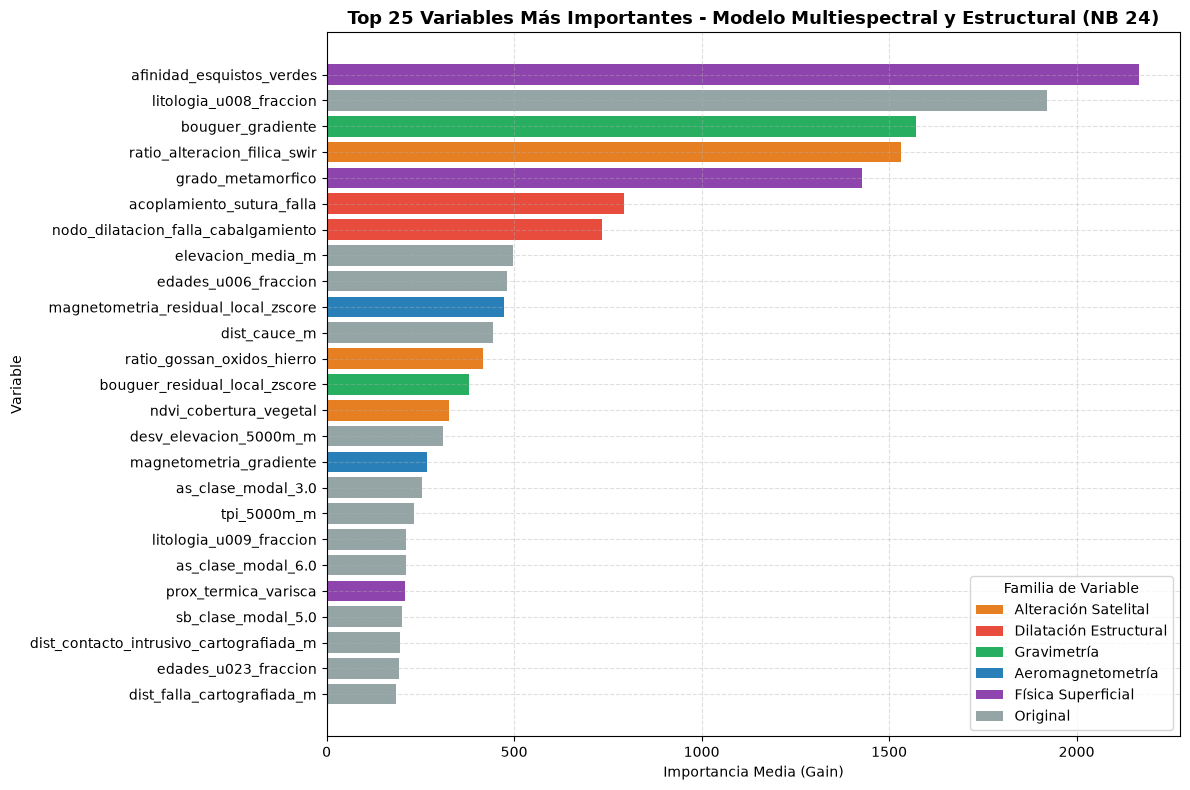

In [8]:
feature_importances = []
for m, pipe in enumerate(members):
    prep = pipe.named_steps['preprocess']
    lgb_booster = pipe.named_steps['model']
    out_names = prep.get_feature_names_out()
    clean_names = [n.split('__')[-1] for n in out_names]
    df_m = pd.DataFrame({'feature': clean_names, 'gain': lgb_booster.booster_.feature_importance(importance_type='gain')})
    agg_m = df_m.groupby('feature')['gain'].sum()
    feature_importances.append(agg_m)

df_imp = pd.concat(feature_importances, axis=1).mean(axis=1).sort_values(ascending=False).reset_index()
df_imp.columns = ['feature', 'importance']

def clasificar_variable(feat):
    if feat in sat_cols:
        return 'Alteración Satelital'
    elif feat in ['dens_falla_1000m', 'nodo_dilatacion_falla_cabalgamiento', 'trampa_dilatacional_reologica', 'acoplamiento_sutura_falla']:
        return 'Dilatación Estructural'
    elif feat in ['bouguer_gradiente', 'bouguer_residual_local_zscore']:
        return 'Gravimetría'
    elif feat in ['magnetometria_gradiente', 'magnetometria_residual_local_zscore']:
        return 'Aeromagnetometría'
    elif feat in ['grado_metamorfico', 'afinidad_esquistos_verdes', 'plutonismo_varisco', 'prox_termica_varisca', 'volcanismo_neogeno', 'contraste_reologico', 'trampa_estructural_reologica']:
        return 'Física Superficial'
    else:
        return 'Original'

df_imp['tipo'] = df_imp['feature'].apply(clasificar_variable)

print("Top 20 Variables por Importancia (Gain):")
display(df_imp.head(20))

# Visualización
plt.figure(figsize=(12, 8))
palette = {
    'Alteración Satelital': '#e67e22',
    'Dilatación Estructural': '#e74c3c',
    'Gravimetría': '#27ae60',
    'Aeromagnetometría': '#2980b9',
    'Física Superficial': '#8e44ad',
    'Original': '#95a5a6'
}
top_25 = df_imp.head(25).iloc[::-1]
bar_colors = [palette.get(t, '#95a5a6') for t in top_25['tipo']]
bars = plt.barh(top_25['feature'], top_25['importance'], color=bar_colors, edgecolor='none')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color, label=label) for label, color in palette.items() if label in top_25['tipo'].values]
plt.legend(handles=legend_elements, title='Familia de Variable', loc='lower right')

plt.title('Top 25 Variables Más Importantes - Modelo Multiespectral y Estructural (NB 24)', fontsize=13, fontweight='bold')
plt.xlabel('Importancia Media (Gain)')
plt.ylabel('Variable')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


## 10. Sellado y Persistencia de Artefactos de la Fase 24

In [9]:
rep_dir = ROOT / 'reports/reentrenamiento_alteracion_hidrotermal_20261021'
rep_dir.mkdir(parents=True, exist_ok=True)

# Guardar favorabilidad nacional
df_fav = pd.DataFrame({
    'cell_id': X_all.index,
    'favorabilidad_alteracion_hidrotermal': ensemble_preds,
    'ratio_alteracion_filica_swir': X_all['ratio_alteracion_filica_swir'].values,
    'ratio_gossan_oxidos_hierro': X_all['ratio_gossan_oxidos_hierro'].values,
    'ndvi_cobertura_vegetal': X_all['ndvi_cobertura_vegetal'].values,
    'anomalia_hidrotermal_multiespectral_zscore': X_all['anomalia_hidrotermal_multiespectral_zscore'].values
})
fav_path = rep_dir / 'favorabilidad_nacional_alteracion_hidrotermal.parquet'
df_fav.to_parquet(fav_path, index=False)
print(f"✓ Favorabilidad guardada: {fav_path} ({len(df_fav):,} celdas)")

# Guardar reportes CSV
df_contrast.to_csv(rep_dir / 'estadisticas_alteracion_hidrotermal.csv', index=False)
df_imp.to_csv(rep_dir / 'importancia_variables_alteracion_hidrotermal.csv', index=False)
df_evolution.to_csv(rep_dir / 'comparativa_evolucion_modelos.csv', index=False)
print(f"✓ Reportes CSV exportados en: {rep_dir}")


✓ Favorabilidad guardada: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_alteracion_hidrotermal_20261021\favorabilidad_nacional_alteracion_hidrotermal.parquet (478,443 celdas)
✓ Reportes CSV exportados en: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_alteracion_hidrotermal_20261021
